1. 일변량 시각화 탐색하기
   - matplotlib을 사용하려면 "figure, plot, show" 3가지를 기억
   - figure: 시각화 하는 영역을 지정, matplotlib.pyplot을 plt 로 선언하고 plt.figure로 사용, 영역과 관련된 매개변수는 figure 내에서 사용
   - plot은 시각화 내용을 표기, 시각화에 사용할 plot의 형태와 매개변수등에 따라 변경, figure와 같은 방식으로 plt와 함께 plt.plot으로 사용
   - show는 시각화한 객체를 출력하며 plt.show으로 사용

- 선그래프(line plot)
  - 시간이나 순서에 따른 데이터의 연속적인 변화량을 관찰할 때 주로 사용되는 그래프, 선 그래프는 수량을 점으로 표시한 후 해당 점을 선으로 이어서 그려주기 때문에 증가와 감소에 대한 상태 변화를 파악하는 데 유용, 예를 들어 시간에 따른 기온변화, 환율변동, 점염병 환자 발생 추이등

In [1]:
# 판다스 불러오기
import pandas as pd

# 데이터 읽어오기
df = pd.read_csv("datasets/Clean_Dataset.csv")

# 지정 인덱스인 첫 번째 칼럼 삭제하기
#df.drop([df.columns[0]], axis=1, inplace=True)

In [2]:
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [3]:
# days_left 별 평균 데이터 만들기
days_left = df.groupby("days_left").mean(numeric_only=True)
days_left.head()

,duration,price
days_left,,
1,14.250228,21591.867151
2,14.111080,30211.299801
3,14.287476,28976.083569
4,13.742667,25730.905653
5,12.921970,26679.773368


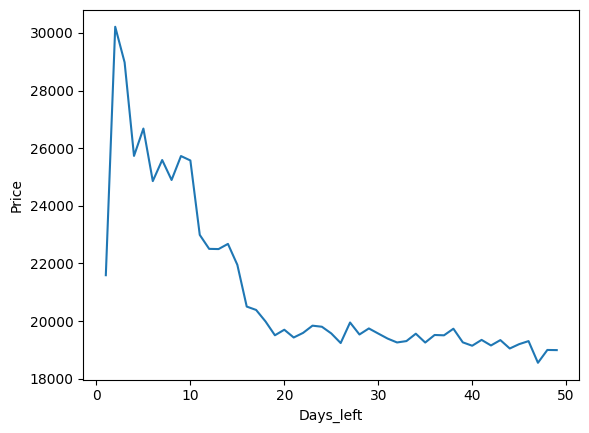

In [4]:
# 시각화 라이브러리 불러오기
import matplotlib.pyplot as plt

# 시각화 영역(figure) 지정하기
plt.figure()

# day_left의 price 데이터로 선 그래프 그리기
plt.plot(days_left["price"])

# X축 이름 지정하기
plt.xlabel("Days_left")

# Y축 이름 지정하기
plt.ylabel("Price")

# 시각화 표기하기
plt.show()

- 막대 그래프(bar plot)
  - 점주에 대한 통계 데이터나 막대 모양으로 나타내는 그래프, 막대 그래프는 각 항목의 수량을 한 눈에 파악하기 쉽고, 크고 작음을 비교 가능
  - 사용 목적이나 가독성을 고려하여 가로, 세로, 누적 그룹화된 막대 그래프를 사용 가능

In [5]:
airline = df.groupby(["airline"]).mean(numeric_only=True)
airline.head()

,duration,days_left,price
airline,,,
AirAsia,8.941714,27.735184,4091.072742
Air_India,15.504235,25.497466,23507.019112
GO_FIRST,8.755380,27.430415,5652.007595
Indigo,5.795197,26.264309,5324.216303
SpiceJet,12.579767,24.122850,6179.278881


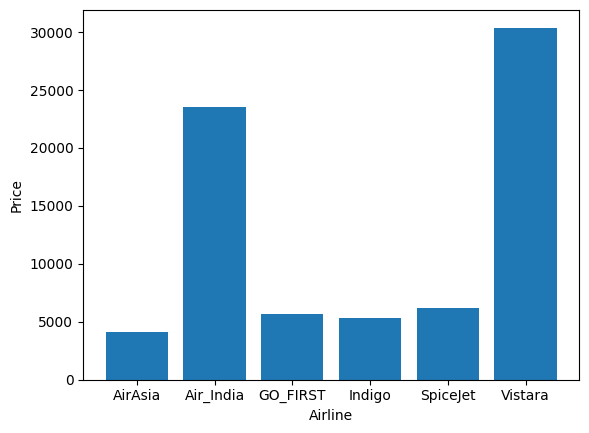

In [6]:
# 인덱스를 리스트로 만들기
label = airline.index
plt.figure()

# 인덱스를 X, 평균 가격을 Y로 하는 막대 그래프 그리기
plt.bar(label, airline["price"])
plt.xlabel("Airline")
plt.ylabel("Price")
plt.show()

- AirIndia 와 Vistara 항공사가 다른 4개의 항공사보다 가격이 비싸다는 것을 바로 확인 가능
- 막대 그래프는 각 항목의 수량을 한눈에 파악하여 크고 작음을 비교하는 데 유용

- 파이 그래프(pie plot)
  - 전체에 대한 각 부분의 비율을 부채꼴 모양으로 나타낸 그래프, 경우에 따라 원형이 아닌 도넛 모양으로 나타내기도 하며, 전체를 100으로 두고 각각의 비율대로 나누어 표기하여 한눈에 알기 쉬움, 점유율, 튜표율, 구성 비율 등을 쉽게 확인 가능

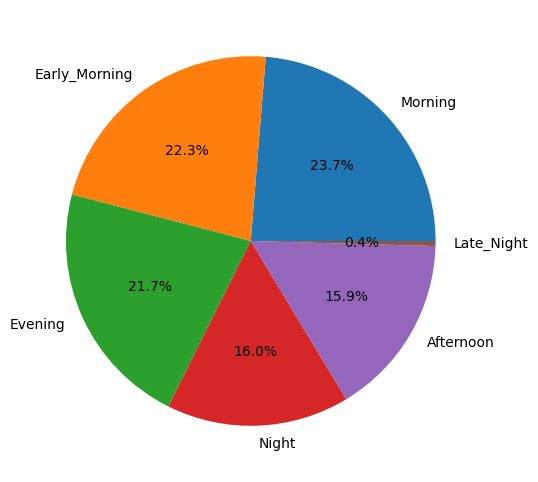

In [7]:
# departure_time 빈도표 데이터 만들기
departure_time = df["departure_time"].value_counts()

plt.figure(figsize=(10, 6))

# departure_time 빈도표 데이터로 파이 그래프 그리기
plt.pie(departure_time, labels=departure_time.index, autopct="%.1f%%")
plt.show()

- 히스토그램(histogram)
  - 특정 데이터의 빈도수를 막대 모양으로 표시한 그래프
  - 히스토그램은 가장 많이 사용되는 통계/분석 도구
  - 가로축에는 계급을, 세로축에는 도수를 지정, 계급은 보톤 변수의 구간을 사용, 해당 구간은 인접하되 겹치지는 않아야 함
  - 데이터의 특성과 분포를 파악하는 역할을 하며 빈도, 빈도밀도, 확률 등의 분포를 그릴 때 사용

/tmp/ipykernel_32920/567350193.py:12: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend("Bin 10", "Bin 20")


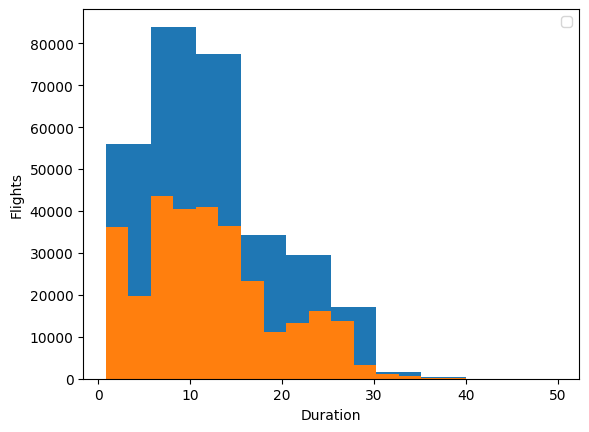

In [8]:
plt.figure()

# duration을 10개 구간으로 나눠서 히스토그램 그리기
plt.hist(df["duration"], bins=10)

# duration을 20개 구간으로 나눠서 히스토그램 그리기
plt.hist(df["duration"], bins=20)
plt.xlabel("Duration")
plt.ylabel("Flights")

# 동시에 3개의 그래프를 하나의 시각화 영역에 그려서 범례 지정하기
plt.legend("Bin 10", "Bin 20")
plt.show()

- 상자 그래프(box plot)
  - 사분위수를 중심으로 수치적 요약 통계를 시각화하는 그래프
  - 수치 자료로 얻어낸 통계량인 5가지(최소값, 제1사분위수, 중앙값, 제3사분위수, 최대값)를 가지고 그래프를 만들어 데이터를 이해하는 데 유용
  - 여기서 최소값과 최대값은 진짜 최소와 최대가 아닌 제3사분위수 + 1.5 * IQR 보다 작은 값 중 최대값, 제1사분위수 - 1.5 * IQR 보다 큰값 중 최소값
  - 정해진 최대값보다 크거나 정해진 최소값보다 작은 값이 이상치(outlier)로 취급되며, 최소값과 최대값을 나타내는 선 밖에 점으로 표기
| 값 | 설명 |
| --- | --- |
| 이상치 | 정해진 최대값보다 크거나, 최소값보다 작은 값 | 
| 최대값 | 제3분위수 + 1.5 * IQR 보다 작은 값 중 최대값 | 
| 제3사분위수 | 제3사분위수(75%)를 나타냄 |
| 중앙값 | 제2사분위수(50%)를 나타냄 | 
| 제1사분위수 | 제1사분위수(25%) | 
| 최소값 | 제1사분위수 - 1.5 * IQR보다 큰 값 중 최소값 |

- IQR(Inrerquartile range)
  - 제3사분위수(75%)에서 제1사분위수(25%)를 뺀 값을 의미

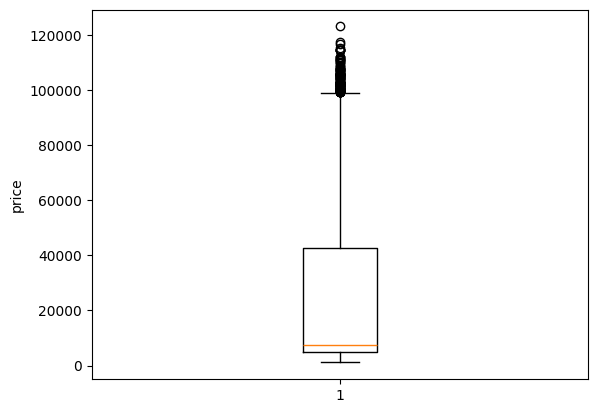

In [9]:
plt.figure()

# Price 칼럼에 대한 상자그래프 그리기
plt.boxplot(list(df["price"]))
plt.ylabel("price")
plt.show()

- 상자그래프에서 알 수 있는 것은 가격 데이터의 범위는 0~120000 사이이지만 중앙값이 10000 정도로 50%의 비행기는 10000이하의 가격으로 판매
- 여러 항목으로 상자 그래프를 만들어서 비교하면 데이터프레임의 boxplot 메소드도 사용 가능
- 데이터프레임의 상자그래프를 활용할때는 by 파라미터에 X축에 해당하는 칼럼명을 Column 파라미터에는 분포를 확인하고자 하는 칼럼명 지정 가느

<Axes: title={'center': 'price'}, xlabel='departure_time'>

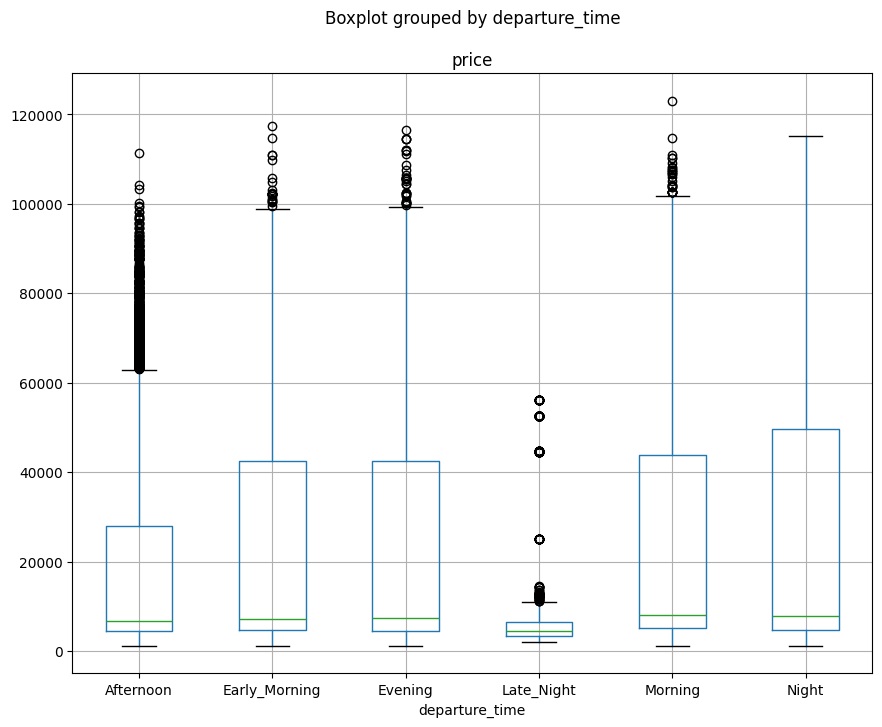

In [10]:
# departure_time 별로 prive에 대한 상자 그래프 그리기
df.boxplot(by="departure_time", column="price", figsize=(10,8))

- 다변량 시각화 탐색하기
  - 산점도(scatter plot)
    - 2개의 연속형 변수의 관계를 보기 위해 좌표의 X축과 Y축에 표시하는 점들을 찍어서 만드는 그래프
    - 산점도에 표기되는 점들은 자료들의 관측값을 나타냄, 키와 몸무게 같은 두 변수간의 상관관계를 대략적으로 확인가능

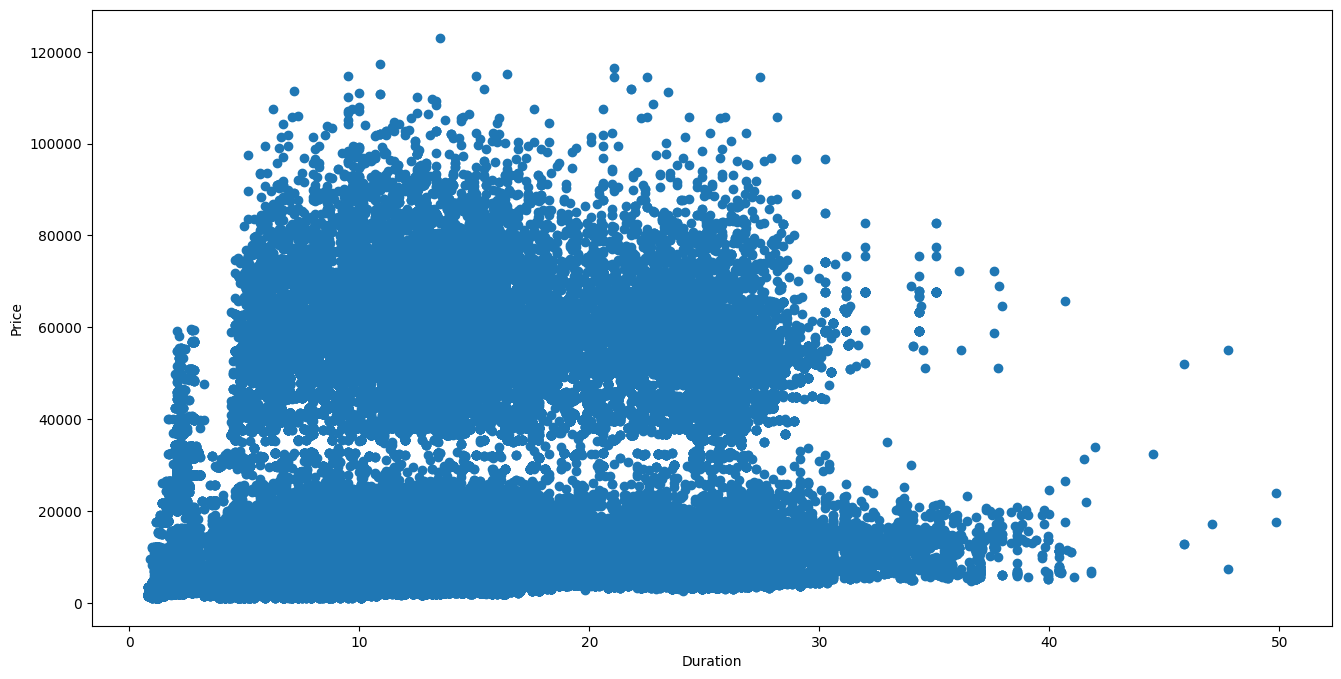

In [11]:
plt.figure(figsize=(16, 8))

# price와 duration의 산점도 그리기
plt.scatter(y=df["price"], x=df["duration"])
plt.xlabel("Duration")
plt.ylabel("Price")
plt.show()

In [12]:
df_eco = df[df["class"] == "Economy"]
df_eco.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


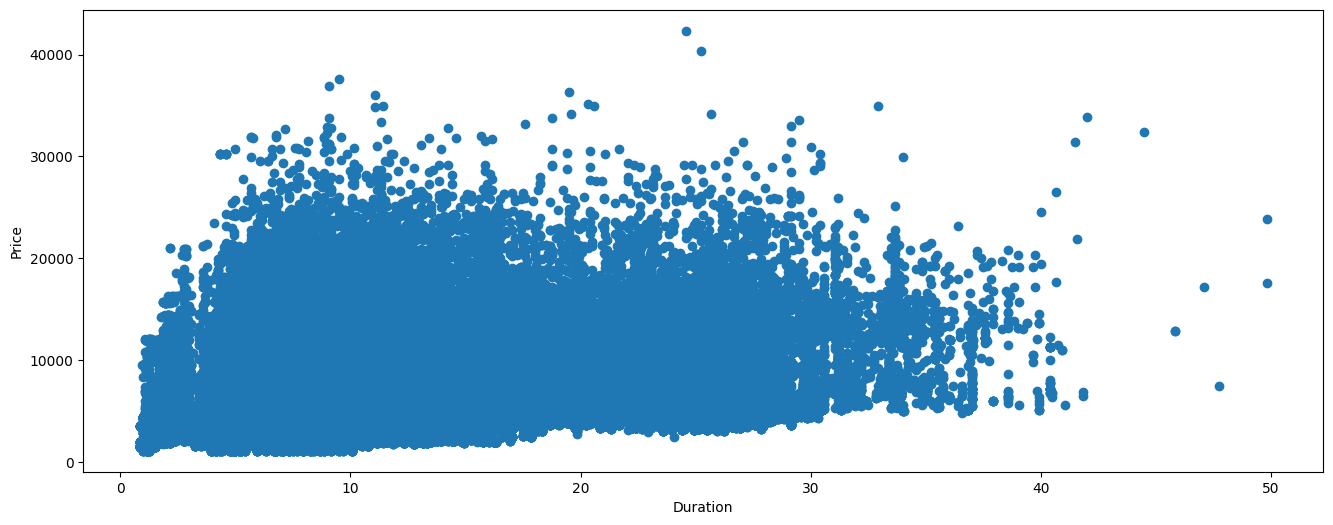

In [13]:
plt.figure(figsize=(16, 6))

# Economy Class에 대한 price와 duration 간의 산점도 그리기
plt.scatter(y=df_eco["price"], x=df_eco["duration"])
plt.xlabel("Duration")
plt.ylabel("Price")
plt.show()

- 히트맵
  - 데이터의 배열을 색상으로 표현해주는 그래프
  - 여러 카테고리 값의 변화를 한눈에 확인 가능
  - matplotlib 라이브러리에서 히트맵은 plt.pcolor() 로 확인 가능
  - 히트맵은 matplotlib보다 시각적인 요소를 표현할 수 있는 seaborn 라이브러리로 진행

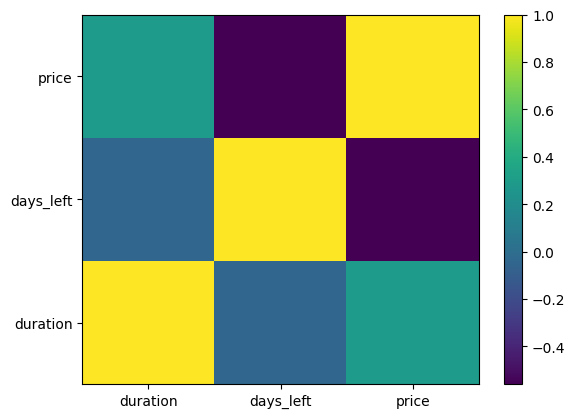

In [14]:
# numpy 불러오기
import numpy as np

# 상관계수 데이터 만들기
heat = df_eco.corr(numeric_only=True)

# 상관계수로 heatmap 그리기
plt.pcolor(heat)

# X축 항목 정보 표기하기
plt.xticks(np.arange(0.5, len(heat.columns), 1), heat.columns)

# Y축 항목 정보 표기하기
plt.yticks(np.arange(0.5, len(heat.index), 1), heat.index)

# 히트맵 확인을 위한 컬러바 표기하기
plt.colorbar()
plt.show()

- matplotlib 활용하기
  - matplotlib와 연관된 함수
    - 주요 함수 설명
      | 함수 | 설명 |
      | --- | --- |
      | figure() | 그래프 객체를 보여줄 영역 지정 |
      | grid(Boolean) | 그래프에 그리드를 표시할 것인지 지정 |
      | show() | 그래프 객체를 화면에 보여줌 |
      | title(str) | 그래프 제목을 문자열(str)로 표시 |
      | xlabel(str) | X축에 문자열(str)이라는 이름을 생성 |
      | xlim([하한, 상한]) | X축의 하한값과 상한값을 설정 |
      | xticks | X축의 눈금과 값의 크기, 기울기 등을 설정 |
      | ylabel(str) | Y축에 문자열(str)이라는 이름을 생성 |
      | ylim([하한, 상한]) | Y축 눈금의 하한값과 상한값을 설정 |
      | yticks | Y축의 눈금값과 크기, 기울기 등을 설정 |

- 범주형 데이터 정재하기
  - 데이터를 분석항 통계를 만들 때 범주형 데이터를 전처리하는 것이 중요
  - 예를 들어 보통 남자, 여자의 구분을 (남, 여) 혹은 (M, W)로 표기하지만 컴퓨터는 0과 1로 변경해 주어야 함
  - 컴퓨터가 데이터를 이해할 수 있도록 범주형(categorical, text) 데이터를 수치형 데이터로 변경하는 과정을 범주형 인코딩(Categorical Encoding)

- 레이블 인코딩하기
  - 레이블 인코딩은 범주형 데이터에 숫자 레이블을 할당
  - 이때 범주형 정렬하는 방법을 많이 사용, 글자를 알파벳순으로 정렬한 후 그것을 기준으로 번호를 지정

In [16]:
# 데이터 구간화 전 원봉 불러오기
df = pd.read_csv("datasets/Clean_Dataset.csv")

# factorize로 airline 컬럼 레이블 인코딩하기
df["label_encoding"] = pd.factorize(df["airline"])[0].reshape(-1,1)
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,label_encoding
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,0
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,0
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,1
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,2
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,2


In [19]:
# airline 칼럼과 새롭게 만들어진 label_encoding 칼럼의 빈도표 확인하기
print(df["airline"].value_counts())
print(df["label_encoding"].value_counts())

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64
label_encoding
2    127859
5     80892
4     43120
3     23173
1     16098
0      9011
Name: count, dtype: int64


In [6]:
import pandas as pd

# 데이터 읽어오기
df = pd.read_csv("datasets/Clean_Dataset.csv")

df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [8]:
# factorize로 airline 칼럼 레이블 인코딩하기
df["label_encoding"] = pd.factorize(df["airline"])[0].reshape(-1, 1)
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,label_encoding
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,0
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,0
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,1
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,2
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,2


In [10]:
# airline 칼럼과 새롭게 만들어진 label_encoding 칼럼의 빈도표 확인하기
print(df["airline"].value_counts())
print(df["label_encoding"].value_counts())

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64
label_encoding
2    127859
5     80892
4     43120
3     23173
1     16098
0      9011
Name: count, dtype: int64


- 원핫 인코딩
  - 순서나 랭크가 없는 카테고리형 데이터를 수치형 데이터로 바꾸는 과정에서 의도하지 않았는데도 알파벳순으로 순번이 생성되고, 그로 인해 생성된 숫자 정보가 모델에 잘못 반영될 수도 있음
  - 이를 해결할 수 있는 방법이 원핫 인코딩(OneHotEncoding)
  - 원핫 인코딩은 1개의 요소는 True, 나머지 요소는 False로 만들어주는 기법, 간단히 말하면 하나의 데이터만 1, 나머지는 0으로 만드는 것
  ![설명](image/원핫%20인코딩의%20원리.png)

In [26]:
# 판다스에서 원핫 인코딩

import pandas as pd

# 데이터 읽어오기
df = pd.read_csv("datasets/Clean_Dataset.csv")

# class 칼럼을 원핫 인코딩하기
pd.get_dummies(df["class"], dtype=int)

,Business,Economy
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1
...,...,...
300148,1,0
300149,1,0
300150,1,0
300151,1,0


- class 칼럼의 값인 Business 와 Economy 라는 컬럼이 만들어지고, 해당 class일 경우 1 아니면 0을 생성

In [27]:
df = pd.get_dummies(df, columns=["class"], dtype=int)
df.head()

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,duration,days_left,price,class_Business,class_Economy
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,2.17,1,5953,0,1
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,2.33,1,5953,0,1
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,2.17,1,5956,0,1
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,2.25,1,5955,0,1
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,2.33,1,5955,0,1
